# Group 8 — Sentiment Analysis of Reviews with Negation
**Course:** Natural Language Processing · **Section:** 3 · **Option:** Review Sentiment Analysis

**Approved proposal question:** Which method performs better on reviews containing negation: TF-IDF with Logistic Regression or a pretrained language model approach?

This is a reproducible Colab notebook comparing **TF-IDF + Logistic Regression** and **pretrained MiniLM sentence embeddings + Logistic Regression**. The pretrained MiniLM encoder is **frozen**: its embeddings are features for a trained classifier, not a fine-tuned transformer.

**Notebook sections:** Setup → Data → Method 1 → Method 2 → Results → Negation & Error Analysis → Try It → Sources.

**Important:** Dataset test labels are held out until final evaluation. New manually written examples are illustrative only, not part of test accuracy. Results are generated by running the notebook, not invented.

## 1. Setup

In [2]:
%pip -q install "sentence-transformers>=3.0,<6" "scikit-learn>=1.4,<2" pandas matplotlib joblib requests

In [1]:
import io, re, os, json, random, zipfile, platform
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests, sklearn, joblib
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sentence_transformers import SentenceTransformer

SEED = 42
random.seed(SEED); np.random.seed(SEED)
OUT = Path('results'); OUT.mkdir(exist_ok=True)
print('Python:', platform.python_version(), 'sklearn:', sklearn.__version__)
print('numpy:', np.__version__, 'pandas:', pd.__version__)


Python: 3.13.18 sklearn: 1.6.1
numpy: 2.4.6 pandas: 2.2.3


## 2. Data: UCI Sentiment Labelled Sentences

The official UCI archive contains 1,000 labelled sentences per source (Amazon, IMDb, Yelp). Labels: **0 = Negative**, **1 = Positive**. No test labels are used for feature selection, training or hyperparameter tuning.

In [3]:
DATA_URL = 'https://archive.ics.uci.edu/static/public/331/sentiment+labelled+sentences.zip'
response = requests.get(DATA_URL, timeout=90)
response.raise_for_status()
files = {'amazon_cells_labelled.txt': 'Amazon', 'imdb_labelled.txt': 'IMDb', 'yelp_labelled.txt': 'Yelp'}
frames = []
with zipfile.ZipFile(io.BytesIO(response.content)) as archive:
    for fname, source in files.items():
        paths = [p for p in archive.namelist() if p.endswith('/'+fname) or p == fname]
        if not paths: raise FileNotFoundError(f'{fname} missing from official archive')
        with archive.open(paths[0]) as handle:
            part = pd.read_csv(handle, sep='\t', names=['text','label'], header=None, encoding='utf-8')
        part['source'] = source
        frames.append(part)
raw = pd.concat(frames, ignore_index=True)
assert set(raw.label.unique()) == {0,1}
print('Raw shape:', raw.shape)
display(pd.crosstab(raw.source, raw.label, margins=True))
display(raw.head())

Raw shape: (2748, 3)


label,0,1,All
source,,,
Amazon,500,500,1000
IMDb,362,386,748
Yelp,500,500,1000
All,1362,1386,2748


,text,label,source
0,So there is no way for me to plug it in here i...,0,Amazon
1,"Good case, Excellent value.",1,Amazon
2,Great for the jawbone.,1,Amazon
3,Tied to charger for conversations lasting more...,0,Amazon
4,The mic is great.,1,Amazon


### Cleaning and duplicate handling

Only whitespace is normalized, preserving negation words, apostrophes, and punctuation. Duplicate text is grouped case-insensitively; text with conflicting labels is removed. We keep one example from each remaining group **before splitting** to prevent identical text leakage.

In [4]:
df = raw.copy()
df['text'] = df['text'].astype(str).str.replace(r'\s+', ' ', regex=True).str.strip()
df = df[df['text'].ne('') & df['label'].isin([0,1])].copy()
df['text_key'] = df['text'].str.casefold()
conflicts = df.groupby('text_key')['label'].nunique()
conflicting_keys = set(conflicts[conflicts > 1].index)
removed_conflicting_rows = df['text_key'].isin(conflicting_keys).sum()
df = df[~df['text_key'].isin(conflicting_keys)].copy()
duplicate_rows = df.duplicated(subset=['text_key']).sum()
df = df.drop_duplicates('text_key').reset_index(drop=True)
print('Original:', len(raw), '| removed conflict rows:', removed_conflicting_rows,
      '| removed repeat rows:', duplicate_rows, '| clean:', len(df))
display(pd.crosstab(df.source, df.label, margins=True))

Original: 2748 | removed conflict rows: 0 | removed repeat rows: 21 | clean: 2727


label,0,1,All
source,,,
Amazon,496,491,987
IMDb,360,384,744
Yelp,497,499,996
All,1353,1374,2727


### Training / development / test split

Use 70% training, 15% development, 15% test. A fixed random seed makes splits reproducible. Class balance is preserved by stratification. Identical text cannot overlap because duplicates were handled first.

In [5]:
train_df, remainder_df = train_test_split(df, test_size=0.30, stratify=df['label'], random_state=SEED)
dev_df, test_df = train_test_split(remainder_df, test_size=0.50,
                                  stratify=remainder_df['label'], random_state=SEED)
for name, frame in [('Train',train_df),('Development',dev_df),('Test',test_df)]:
    print(name, len(frame), 'labels:', frame['label'].value_counts().to_dict())
assert not (set(train_df.text_key) & set(dev_df.text_key))
assert not (set(train_df.text_key) & set(test_df.text_key))
assert not (set(dev_df.text_key) & set(test_df.text_key))
train_df.to_csv(OUT/'train_split.csv', index=False)
dev_df.to_csv(OUT/'dev_split.csv', index=False)
test_df.to_csv(OUT/'test_split.csv', index=False)

Train 1908 labels: {1: 961, 0: 947}
Development 409 labels: {1: 206, 0: 203}
Test 410 labels: {1: 207, 0: 203}


## 3. Method 1 — TF-IDF + Logistic Regression

Select regularization strength **using development data only**. The TF-IDF vocabulary and model are fitted exclusively on the training data.

In [6]:
X_train, y_train = train_df.text.tolist(), train_df.label.to_numpy()
X_dev, y_dev = dev_df.text.tolist(), dev_df.label.to_numpy()
X_test, y_test = test_df.text.tolist(), test_df.label.to_numpy()
C_GRID = [0.1, 1.0, 10.0]
traditional_trials = []
for c in C_GRID:
    pipe = Pipeline([
        ('tfidf', TfidfVectorizer(ngram_range=(1,2), lowercase=True,
                                  strip_accents='unicode', min_df=1)),
        ('clf', LogisticRegression(C=c, max_iter=2000, random_state=SEED))
    ])
    pipe.fit(X_train, y_train)
    traditional_trials.append((f1_score(y_dev,pipe.predict(X_dev),average='macro'),c,pipe))
traditional_trials.sort(key=lambda x: (-x[0], x[1]))
best_tfidf_f1, best_tfidf_c, tfidf_model = traditional_trials[0]
print('Chosen TF-IDF LogisticRegression C:',best_tfidf_c, '| development Macro-F1:',round(best_tfidf_f1,4))
joblib.dump(tfidf_model, OUT/'tfidf_logreg.joblib')

Chosen TF-IDF LogisticRegression C: 10.0 | development Macro-F1: 0.8435


['results/tfidf_logreg.joblib']

## 4. Method 2 — Pretrained MiniLM Embeddings + Logistic Regression

Load pretrained `sentence-transformers/all-MiniLM-L6-v2`; encode sentences into vectors. Train only the classifier on train embeddings, and choose classifier `C` on development embeddings. The pretrained encoder is not fine-tuned.

In [7]:
ENCODER_ID = 'sentence-transformers/all-MiniLM-L6-v2'
encoder = SentenceTransformer(ENCODER_ID)
train_emb = encoder.encode(X_train, batch_size=32, show_progress_bar=True, normalize_embeddings=True)
dev_emb = encoder.encode(X_dev, batch_size=32, show_progress_bar=True, normalize_embeddings=True)
# Test embeddings contain input text only. Do not inspect test labels until final evaluation.
test_emb = encoder.encode(X_test, batch_size=32, show_progress_bar=True, normalize_embeddings=True)
pretrained_trials = []
for c in C_GRID:
    clf = LogisticRegression(C=c, max_iter=2000, random_state=SEED)
    clf.fit(train_emb, y_train)
    pretrained_trials.append((f1_score(y_dev,clf.predict(dev_emb),average='macro'),c,clf))
pretrained_trials.sort(key=lambda x: (-x[0],x[1]))
best_pretrained_f1, best_pretrained_c, pretrained_clf = pretrained_trials[0]
print('Chosen MiniLM classifier C:', best_pretrained_c, '| development Macro-F1:',round(best_pretrained_f1,4))
joblib.dump(pretrained_clf, OUT/'minilm_logreg.joblib')
(OUT/'encoder_id.txt').write_text(ENCODER_ID, encoding='utf-8')

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (8 outputs left out)

Batches:   0%|          | 0/13 [00:00<?, ?it/s]

Batches:   0%|          | 0/13 [00:00<?, ?it/s]

Chosen MiniLM classifier C: 0.1 | development Macro-F1: 0.9022


38

## 5. Final Test Evaluation

Both methods are evaluated **once on the same held-out test rows**, using accuracy and macro F1. No hyperparameters are selected based on these results.

,Method,Accuracy,Macro F1,Dev Macro F1
0,TF-IDF + Logistic Regression,0.8317,0.8317,0.8435
1,MiniLM embeddings + Logistic Regression,0.8902,0.8902,0.9022



TF-IDF
              precision    recall  f1-score   support

    Negative       0.83      0.84      0.83       203
    Positive       0.84      0.83      0.83       207

    accuracy                           0.83       410
   macro avg       0.83      0.83      0.83       410
weighted avg       0.83      0.83      0.83       410



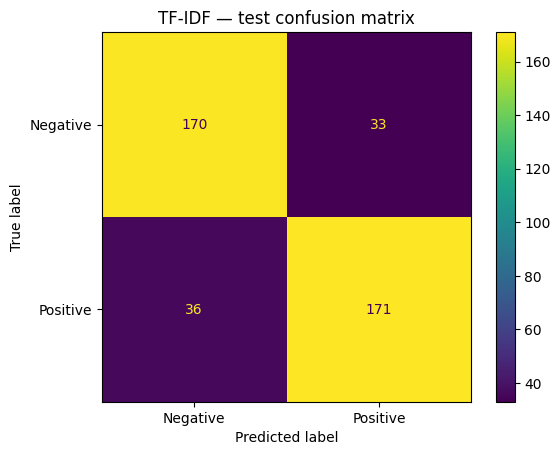


MiniLM
              precision    recall  f1-score   support

    Negative       0.87      0.91      0.89       203
    Positive       0.91      0.87      0.89       207

    accuracy                           0.89       410
   macro avg       0.89      0.89      0.89       410
weighted avg       0.89      0.89      0.89       410



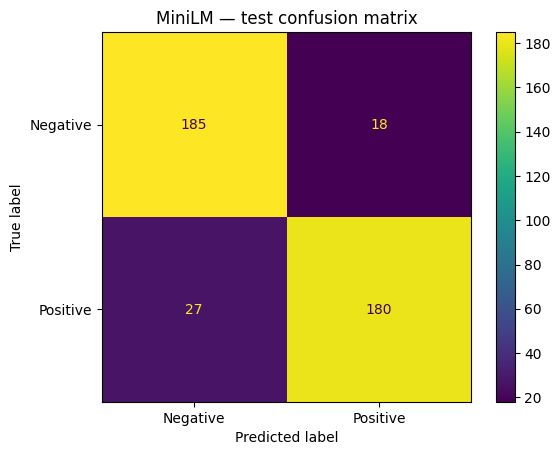

In [8]:
tfidf_pred = tfidf_model.predict(X_test)
minilm_pred = pretrained_clf.predict(test_emb)
metrics = pd.DataFrame([
    {'Method':'TF-IDF + Logistic Regression', 'Accuracy':accuracy_score(y_test,tfidf_pred),
     'Macro F1':f1_score(y_test,tfidf_pred,average='macro'), 'Dev Macro F1':best_tfidf_f1},
    {'Method':'MiniLM embeddings + Logistic Regression', 'Accuracy':accuracy_score(y_test,minilm_pred),
     'Macro F1':f1_score(y_test,minilm_pred,average='macro'), 'Dev Macro F1':best_pretrained_f1}
])
display(metrics.round(4))
metrics.to_csv(OUT/'model_comparison.csv',index=False)
for title,preds in [('TF-IDF',tfidf_pred),('MiniLM',minilm_pred)]:
    print('\n'+title+'\n'+classification_report(y_test,preds,target_names=['Negative','Positive'],zero_division=0))
    ConfusionMatrixDisplay.from_predictions(y_test,preds,display_labels=['Negative','Positive'])
    plt.title(title+' — test confusion matrix'); plt.show()

## 6. Negation Challenge and Error Analysis

A **predefined** regular expression identifies a negation subgroup within the held-out test set, without changing or selecting the models. Because a randomly drawn dataset might contain relatively few negation reviews, show its sample size and avoid claiming a strong conclusion if it is small. A separate manually written set is for demonstration only.

In [9]:
NEGATION_PATTERN = r"\b(?:not|no|never|none|nothing|nobody|neither|nor|cannot|can't|won't|don't|doesn't|didn't|isn't|aren't|wasn't|weren't|wouldn't|couldn't|shouldn't|haven't|hasn't|hadn't|without|hardly|barely)\b"
neg_mask = test_df.text.str.contains(NEGATION_PATTERN, flags=re.IGNORECASE, regex=True).to_numpy()
print('Negation subset size:', int(neg_mask.sum()), 'of', len(test_df))
neg_metrics = []
for method,preds in [('TF-IDF + Logistic Regression',tfidf_pred),('MiniLM embeddings + Logistic Regression',minilm_pred)]:
    neg_metrics.append({'Method':method, 'Negation Test N':int(neg_mask.sum()),
                        'Negation Accuracy':accuracy_score(y_test[neg_mask],preds[neg_mask]) if neg_mask.any() else np.nan,
                        'Negation Macro F1':f1_score(y_test[neg_mask],preds[neg_mask],average='macro',zero_division=0) if neg_mask.any() else np.nan})
neg_table = pd.DataFrame(neg_metrics)
display(neg_table.round(4)); neg_table.to_csv(OUT/'negation_comparison.csv',index=False)
errors = test_df[['text','label','source']].copy().reset_index(drop=True)
errors['tfidf_prediction'] = tfidf_pred
errors['minilm_prediction'] = minilm_pred
errors['has_negation'] = neg_mask
errors['tfidf_wrong'] = errors.label != errors.tfidf_prediction
errors['minilm_wrong'] = errors.label != errors.minilm_prediction
errors['either_wrong'] = errors.tfidf_wrong | errors.minilm_wrong
errors.to_csv(OUT/'test_predictions_and_errors.csv',index=False)
# Prioritize wrong cases containing negation, then other errors.
selected = errors[errors.either_wrong].sort_values(['has_negation'],ascending=False).head(10)
print('Wrong predictions (discuss at least 3 in report; explain negation/ambiguity/domain):')
display(selected[['text','source','label','tfidf_prediction','minilm_prediction','has_negation']])
selected.to_csv(OUT/'error_examples_to_explain.csv',index=False)

Negation subset size: 94 of 410


,Method,Negation Test N,Negation Accuracy,Negation Macro F1
0,TF-IDF + Logistic Regression,94,0.8085,0.6908
1,MiniLM embeddings + Logistic Regression,94,0.7872,0.6934


Wrong predictions (discuss at least 3 in report; explain negation/ambiguity/domain):


,text,source,label,tfidf_prediction,minilm_prediction,has_negation
408,I was looking for this headset for a long time...,Amazon,1,0,1,True
38,I promise they won't disappoint.,Yelp,1,0,0,True
112,My drink was never empty and he made some real...,Yelp,1,1,0,True
321,"Not to mention the combination of pears, almon...",Yelp,1,0,1,True
324,The ambiance here did not feel like a buffet s...,Yelp,0,0,1,True
98,I usually don't like headbands but this one is...,Amazon,1,0,1,True
130,The building itself seems pretty neat; the bat...,Yelp,0,1,1,True
90,The goat taco didn't skimp on the meat and wow...,Yelp,1,0,0,True
232,The film deserves strong kudos for taking this...,IMDb,1,0,1,True
338,It's also great to see that renowned silent sc...,IMDb,1,1,0,True


### Illustrative new review pairs (not test data)

These original examples are useful for investigating sentiment flips. They are **not** labelled test data and must not be included in test accuracy or macro F1. The team should replace/add two original labelled examples per member in their appendix.

In [10]:
original_examples = [
    ('The service was excellent.',1),
    ('The service was not excellent.',0),
    ('The movie was interesting.',1),
    ('The movie was not interesting.',0),
    ('I would recommend this product.',1),
    ('I would never recommend this product.',0),
    ('The food was good.',1),
    ('The food was not good.',0),
]
example_texts = [x[0] for x in original_examples]
example_emb = encoder.encode(example_texts,normalize_embeddings=True)
examples_df = pd.DataFrame({'Original example':example_texts,
                            'Illustrative human label':[x[1] for x in original_examples],
                            'TF-IDF prediction':tfidf_model.predict(example_texts),
                            'MiniLM prediction':pretrained_clf.predict(example_emb)})
display(examples_df)
examples_df.to_csv(OUT/'original_examples_not_test.csv',index=False)

,Original example,Illustrative human label,TF-IDF prediction,MiniLM prediction
0,The service was excellent.,1,1,1
1,The service was not excellent.,0,0,0
2,The movie was interesting.,1,1,1
3,The movie was not interesting.,0,0,0
4,I would recommend this product.,1,1,1
5,I would never recommend this product.,0,1,0
6,The food was good.,1,1,1
7,The food was not good.,0,0,0


## 7. Try it — classify unfamiliar reviews (no retraining)

Input can be changed freely after both models have been trained. Empty input is handled. Use `model_choice = "minilm"` or `"tfidf"`.

In [11]:
def predict_review(review, model_choice='minilm'):
    if not isinstance(review,str) or not review.strip():
        return 'Please enter a non-empty review.'
    review = ' '.join(review.split())
    if model_choice == 'tfidf':
        label = int(tfidf_model.predict([review])[0])
    elif model_choice == 'minilm':
        vector = encoder.encode([review],normalize_embeddings=True)
        label = int(pretrained_clf.predict(vector)[0])
    else:
        return 'Please choose tfidf or minilm.'
    return 'Positive' if label == 1 else 'Negative'

review_text = 'The product was not worth the money.'  # change this text
model_choice = 'minilm'  # change to 'tfidf' to try method 1
print('Input:',review_text)
print('Prediction:',predict_review(review_text,model_choice))
print('Empty input check:',predict_review(' ',model_choice))

Input: The product was not worth the money.
Prediction: Negative
Empty input check: Please enter a non-empty review.


## 8. Export evidence for report and presentation

In [12]:
run_info = {
    'dataset':DATA_URL,'raw_rows':len(raw),'clean_rows':len(df),
    'train_rows':len(train_df),'dev_rows':len(dev_df),'test_rows':len(test_df),
    'negation_test_rows':int(neg_mask.sum()),'seed':SEED,
    'method1':'TF-IDF (1,2)-gram + LogisticRegression',
    'method2':ENCODER_ID+' frozen embeddings + LogisticRegression',
    'method1_best_C':best_tfidf_c,'method2_best_C':best_pretrained_c,
    'model_results':metrics.to_dict(orient='records'),
    'negation_results':neg_table.to_dict(orient='records'),
    'package_versions':{'python':platform.python_version(),'sklearn':sklearn.__version__,
                        'numpy':np.__version__,'pandas':pd.__version__}
}
(OUT/'run_summary.json').write_text(json.dumps(run_info,indent=2),encoding='utf-8')
print('Saved evidence files:')
for f in sorted(OUT.iterdir()): print('-',f)
# Optional Colab results download:
# !zip -qr NLP_Group8_Results.zip results
# from google.colab import files
# files.download('NLP_Group8_Results.zip')

Saved evidence files:
- results/dev_split.csv
- results/encoder_id.txt
- results/error_examples_to_explain.csv
- results/minilm_logreg.joblib
- results/model_comparison.csv
- results/negation_comparison.csv
- results/original_examples_not_test.csv
- results/run_summary.json
- results/test_predictions_and_errors.csv
- results/test_split.csv
- results/tfidf_logreg.joblib
- results/train_split.csv


In [13]:

import shutil
from google.colab import files

shutil.make_archive("Group8_Results", "zip", "results")
files.download("Group8_Results.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 9. Sources, attribution and study guidance

- UCI Machine Learning Repository: [Sentiment Labelled Sentences](https://archive.ics.uci.edu/dataset/331/sentiment+labelled+sentences) — dataset source.
- Maas et al. (2011), *Learning Word Vectors for Sentiment Analysis*, ACL — cited by approved proposal.
- Reimers and Gurevych (2019), *Sentence-BERT: Sentence Embeddings using Siamese BERT-Networks*, EMNLP — cited by approved proposal.
- [Sentence Transformers documentation](https://sbert.net/docs/sentence_transformer/usage/usage.html) — pretrained feature extraction.
- [Scikit-learn documentation](https://scikit-learn.org/stable/) — TF-IDF, Logistic Regression and metrics.

**AI use disclosure:** Initial notebook structure and code were drafted with ChatGPT and should be acknowledged in the report. Group members are responsible for reviewing, executing, testing, describing and modifying the code; record dated screenshots/commits as individual evidence.

**Research integrity:** Do not quote accuracy values until this notebook has run successfully. Explain at least three genuine test errors and any limitations of the negation subset. Group 8 has four members per the submitted, instructor-approved proposal.